Follow-up concept: testing whether validating on a higher-volatility period works better for 2026.

In [1]:
import sys
sys.path.append("..")
import itertools
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from src.data import load_dataset
from src.backtest import walk_forward
from src.features import make_lag_features
from src.models import random_walk_forecast, var_forecast, xgb_forecast
from src.metrics import compare_models_staggered, accuracy_metrics, dm_table, plot_forecasts

H = 5   # forecast horizon: 1 in this notebook, 5 in the other

data = load_dataset()
PRICES = ["brent_spot", "wti", "usd", "sp500"]  # prices -> log returns
INDICES = ["vix", "ovx", "epu", "gpr"]  # fear/uncertainty indices -> log levels
CHANGES = ["invt_weekly_change"]  # alr in percent -> no need do log diff

X = pd.DataFrame(index=data.index)
for col in PRICES:
    X[col] = np.log(data[col]).diff()
for col in INDICES:
    X[col] = np.log(data[col])
for col in CHANGES:
    X[col] = data[col]
X = X.dropna()

df_var = X.rename(columns={"brent_spot": "log_return"})
df_var["brent_spot"] = data["brent_spot"]


/Users/airrehn/codebase/oil-trading-5210/venv/lib/python3.11/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [2]:
from src.features import garch_volatility

volatility = garch_volatility(df_var, col="log_return") * 100   # daily GARCH vol in %
periods = {
    "Validation 2024-25": volatility["2024-01-01":"2025-12-31"],
    "Validation 2022": volatility["2022-01-01":"2022-12-31"],
    "Test Jan-Sep 2026": volatility["2026-01-01":"2026-09-30"],
}

vol_table = pd.DataFrame({name: {"Average vol %": v.mean(), "Median vol %": v.median(), "Max vol %": v.max()}
                          for name, v in periods.items()}).T
vol_table["Gap to test average"] = vol_table.loc["Test Jan-Sep 2026", "Average vol %"] - vol_table["Average vol %"]
vol_table.round(2)


,Average vol %,Median vol %,Max vol %,Gap to test average
Validation 2024-25,1.87,1.78,3.71,2.13
Validation 2022,2.90,2.67,5.50,1.11
Test Jan-Sep 2026,4.01,3.90,7.19,0.00


We see 2022 has a closer volatility to the rockier average of 2026.

VAR 

In [3]:
from statsmodels.tsa.api import VAR                # the VAR model used for the Granger test

pre = X[X.index < "2022-01-01"]                    # only data before validation, so no peeking
pre_var = pre.reset_index(drop=True)               # drop the dates to stop statsmodels warnings
order = VAR(pre_var).select_order(maxlags=10)      # try lags up to 10
var_fit = VAR(pre_var).fit(order.bic)              # fit using the lag BIC picks
granger = pd.Series({col: var_fit.test_causality(caused="brent_spot", causing=[col], kind="f").pvalue
                     for col in pre.columns if col != "brent_spot"}).sort_values()   # p-value per variable, smallest first
print(granger)

STAGES = {                                         # log_return stays first: var_forecast reads column 0 as Brent
    "S1": ["log_return"] + list(granger[granger < 0.001].index),      # strongest variables
    "S2": ["log_return"] + list(granger[granger < 0.05 / 8].index),   # pass the Bonferroni cut
    "S3": ["log_return"] + list(granger[granger < 0.5].index),        # everything except the clearly useless
}
print(STAGES)


wti                   2.137378e-43
usd                   3.116949e-04
epu                   1.181989e-03
vix                   3.723588e-03
sp500                 1.880616e-02
invt_weekly_change    3.321201e-02
ovx                   6.055691e-02
gpr                   6.134008e-01
dtype: float64
{'S1': ['log_return', 'wti', 'usd'], 'S2': ['log_return', 'wti', 'usd', 'epu', 'vix'], 'S3': ['log_return', 'wti', 'usd', 'epu', 'vix', 'sp500', 'invt_weekly_change', 'ovx']}


WTI and USD are strongest (p < 0.001). EPU and VIX also pass the Bonferroni cut (5%/8 = 0.00625). S&P 500, inventory and OVX are weaker, and GPR is clearly not useful (p = 0.61).

In [4]:
val_args = dict(horizon=H, start_date="2022-01-01", end_date="2022-12-31", target_end_date="2022-12-31")

results = {"Random Walk": walk_forward(df_var, forecast_funct=random_walk_forecast, **val_args)}

for stage, cols in STAGES.items():
    for p in range(1, 6):
        results[f"VAR {stage} p={p}"] = walk_forward(df_var, forecast_funct=var_forecast, cols=cols, lags=p, **val_args)


In [5]:
table = compare_models_staggered(results, horizon=H)[["MAE", "RMSE", "MAPE", "directional_accuracy", "sharpe_ratio"]]
for m in ["MAE", "RMSE", "MAPE"]:
    table[f"{m}_vs_RW_%"] = (1 - table[m] / table.loc["Random Walk", m]) * 100
table.round(4).sort_values("MAPE")

,MAE,RMSE,MAPE,directional_accuracy,sharpe_ratio,MAE_vs_RW_%,RMSE_vs_RW_%,MAPE_vs_RW_%
model,,,,,,,,
VAR S1 p=3,5.3435,7.1084,5.1679,0.5385,-0.6000,0.4616,-0.6496,0.5483
VAR S1 p=2,5.3667,7.1371,5.1930,0.5223,-0.2894,0.0290,-1.0554,0.0650
Random Walk,5.3683,7.0625,5.1964,0.0000,NaN,0.0000,0.0000,0.0000
VAR S1 p=1,5.3698,7.1057,5.1993,0.5263,-0.8942,-0.0282,-0.6118,-0.0566
VAR S1 p=5,5.4150,7.2083,5.2324,0.4939,-0.5359,-0.8709,-2.0635,-0.6925
VAR S2 p=1,5.4122,7.1442,5.2430,0.4696,-1.0509,-0.8188,-1.1563,-0.8972
VAR S1 p=4,5.4289,7.2402,5.2460,0.5101,-1.0881,-1.1288,-2.5159,-0.9547
VAR S2 p=3,5.4327,7.1731,5.2585,0.4980,0.1513,-1.2009,-1.5663,-1.1952
VAR S2 p=2,5.4478,7.1963,5.2730,0.4777,-1.0465,-1.4810,-1.8945,-1.4738


In [6]:
val_args = dict(horizon=H, start_date="2022-01-01", end_date="2022-12-31", target_end_date="2022-12-31")
TIE = 0.002   # a variable must cut MAPE by more than this to be added

rw = walk_forward(df_var, forecast_funct=random_walk_forecast, **val_args)
best_mape = accuracy_metrics(rw)["MAPE"]   # starting point: the random walk
best_lag = None
print(f"Random walk MAPE: {best_mape:.4f}")

selected = ["log_return"]
remaining = ["wti", "usd", "sp500", "vix", "ovx", "epu", "gpr", "invt_weekly_change"]

while remaining:
    jobs = [(var, lag) for var in remaining for lag in range(1, 6)]
    runs = Parallel(n_jobs=-1)(
        delayed(walk_forward)(df_var, forecast_funct=var_forecast, cols=selected + [var], lags=lag, **val_args)
        for var, lag in jobs
    )
    scores = pd.DataFrame([{"var": var, "lag": lag, "MAPE": accuracy_metrics(r)["MAPE"]}
                           for (var, lag), r in zip(jobs, runs)])
    best = scores.loc[scores["MAPE"].idxmin()]
    print(f"Round {len(selected)}: best add = {best['var']} (lag={best['lag']}), MAPE {best['MAPE']:.4f} vs current {best_mape:.4f}")
    if best["MAPE"] > best_mape - TIE:
        print("Improvement < 0.002, not useful anymore, stop.")
        break
    selected.append(best["var"])
    remaining.remove(best["var"])
    best_mape, best_lag = best["MAPE"], best["lag"]

print("Selected:", selected, "lag =", best_lag)


Random walk MAPE: 5.1964
Round 1: best add = wti (lag=3), MAPE 5.1696 vs current 5.1964
Round 2: best add = sp500 (lag=3), MAPE 5.1654 vs current 5.1696
Round 3: best add = usd (lag=3), MAPE 5.1601 vs current 5.1654
Round 4: best add = invt_weekly_change (lag=3), MAPE 5.1625 vs current 5.1601
Improvement < 0.002, not useful anymore, stop.
Selected: ['log_return', 'wti', 'sp500', 'usd'] lag = 3


In [7]:
stage_rows = table[table.index.str.startswith("VAR")]
print(f"Best hierarchical: {stage_rows['MAPE'].idxmin()}, MAPE {stage_rows['MAPE'].min():.4f}")
print(f"Forward selection: {selected}, lag {best_lag}, MAPE {best_mape:.4f}")


Best hierarchical: VAR S1 p=3, MAPE 5.1679
Forward selection: ['log_return', 'wti', 'sp500', 'usd'], lag 3, MAPE 5.1601


Forward Selection (FS) won with MAPE 5.1601 (+0.70% vs RW), against the best hierarchical model, VAR S1 p=3, at 5.1679 (+0.55%). The gap of 0.0078 is above our 0.002 tie, so we use the FS model: wti, sp500, usd, lag 3.

XGBoost

In [8]:
feats_fs = make_lag_features(df_var, selected, lags=best_lag)   # same variables and same days as the VAR

grid = [dict(n_estimators=n, max_depth=d, min_child_weight=m)
        for n, d, m in itertools.product([50, 200], [1, 2], [1, 100])]
runs = Parallel(n_jobs=-1)(
    delayed(walk_forward)(df_var, forecast_funct=xgb_forecast, features=feats_fs, **g, **val_args) for g in grid
)

mapes = [accuracy_metrics(r)["MAPE"] for r in runs]
xgb_params = grid[np.argmin(mapes)]   # the settings with the smallest MAPE
print("Best XGB:", xgb_params, f"MAPE {min(mapes):.4f}")


Best XGB: {'n_estimators': 50, 'max_depth': 1, 'min_child_weight': 1} MAPE 5.2380


On Test set:

Jan-Sep 2026 n = 184


,MAE,RMSE,MAPE,directional_accuracy,sharpe_ratio,MAPE_vs_RW_%
model,,,,,,
VAR,7.2369,9.4811,7.4266,0.4565,-0.2106,0.6366
Random Walk,7.2934,9.5418,7.4742,0.0000,NaN,0.0000
XGB,7.3003,9.5535,7.4941,0.5652,1.5490,-0.2665


,DM_stat,p_value,n
VAR,-0.6626,0.5084,184.0
XGB,0.1913,0.8485,184.0


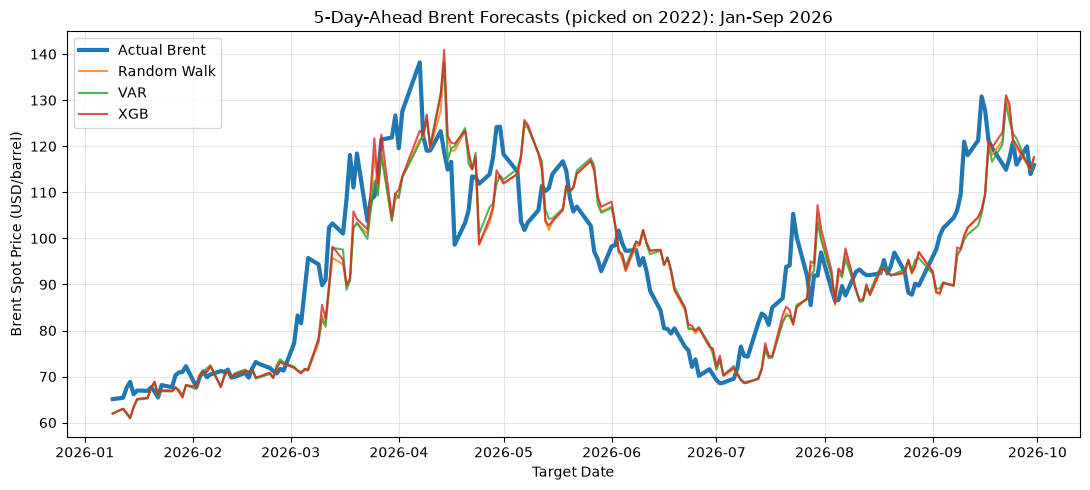

October 2026 n = 12


,MAE,RMSE,MAPE,directional_accuracy,sharpe_ratio,MAPE_vs_RW_%
model,,,,,,
VAR,6.4925,7.8994,5.3032,0.5000,-4.6294,3.9327
Random Walk,6.7917,8.2477,5.5203,0.0000,NaN,0.0000
XGB,7.1136,8.3640,5.7860,0.4167,-9.2329,-4.8131


,DM_stat,p_value,n
VAR,-1.0713,0.3070,12.0
XGB,0.8062,0.4372,12.0


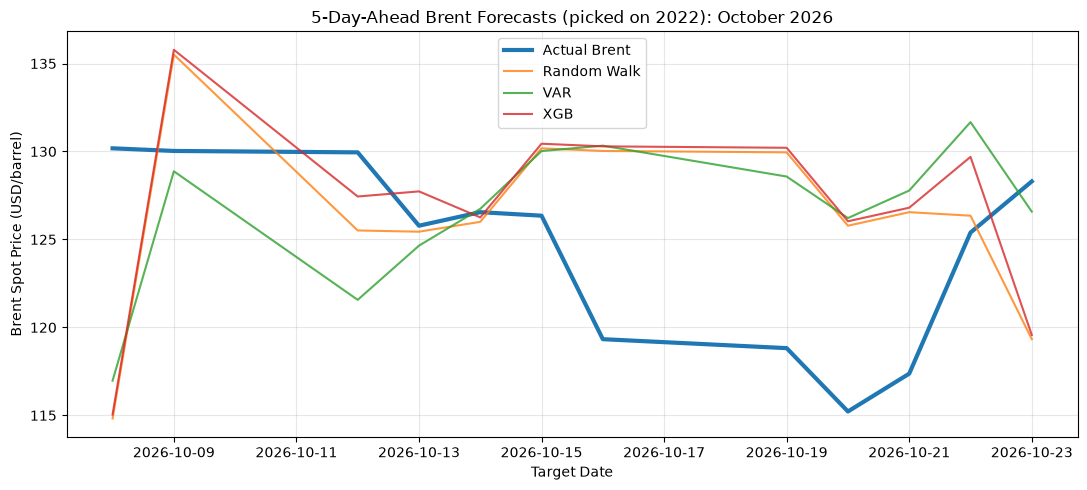

In [11]:
TESTS = {
    "Jan-Sep 2026": dict(start_date="2026-01-01", end_date="2026-09-30", target_end_date="2026-09-30"),
    "October 2026": dict(start_date="2026-10-01", end_date="2026-10-23", target_end_date="2026-10-23", fit_end_date="2026-09-30"),
}

all_results = {}   # stores each test's results for plotting later
for label, dates in TESTS.items():
    test_args = dict(horizon=H, **dates)
    test_results = {
        "Random Walk": walk_forward(df_var, forecast_funct=random_walk_forecast, **test_args),
        "VAR": walk_forward(df_var, forecast_funct=var_forecast, cols=selected, lags=best_lag, **test_args),
        "XGB": walk_forward(df_var, forecast_funct=xgb_forecast, features=feats_fs, **xgb_params, **test_args),
    }
    all_results[label] = test_results   # save this test before the next pass overwrites it

    table = compare_models_staggered(test_results, horizon=H)[["MAE", "RMSE", "MAPE", "directional_accuracy", "sharpe_ratio"]]
    table["MAPE_vs_RW_%"] = (1 - table["MAPE"] / table.loc["Random Walk", "MAPE"]) * 100

    print(label, "n =", len(test_results["Random Walk"]))
    display(table.round(4).sort_values("MAPE"))
    display(dm_table(test_results, horizon=H).round(4))   # -ve DM stat = errors smaller than RW
    plot_forecasts(test_results, f"{H}-Day-Ahead Brent Forecasts (picked on 2022): {label}")


Isolating VAR (lowest MAPE)

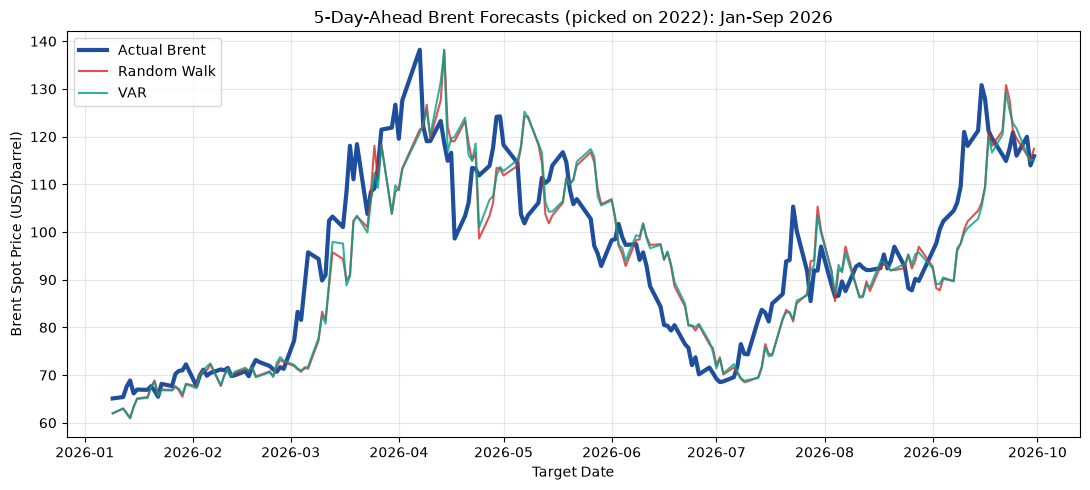

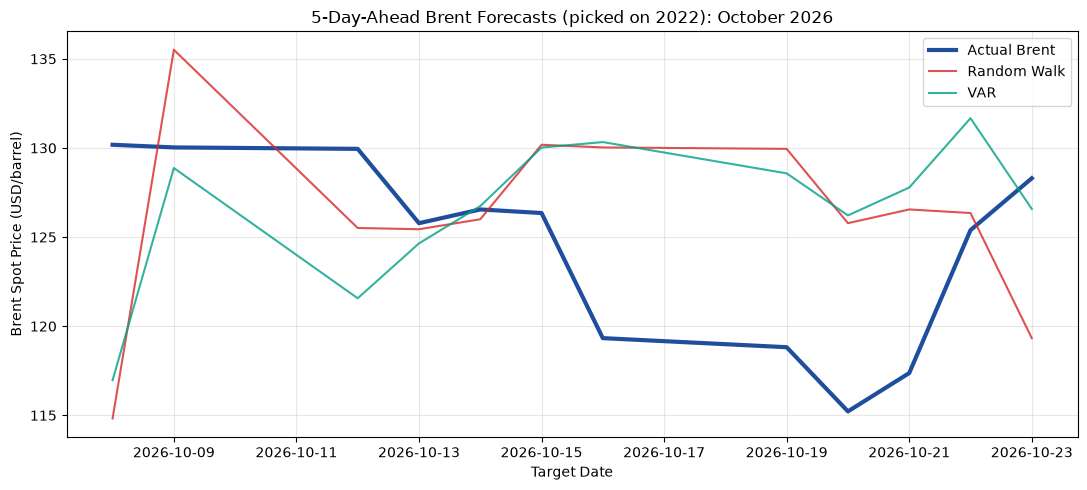

In [ ]:
models = ["Random Walk", "VAR"]

plot_forecasts(all_results["Jan-Sep 2026"], f"{H}-Day-Ahead Brent Forecasts (picked on 2022): Jan-Sep 2026", models=models)
plot_forecasts(all_results["October 2026"], f"{H}-Day-Ahead Brent Forecasts (picked on 2022): October 2026", models=models)

Comparing the two VARs in October. (The older one picked on 2024-25 validation in forecast5.ipynb)

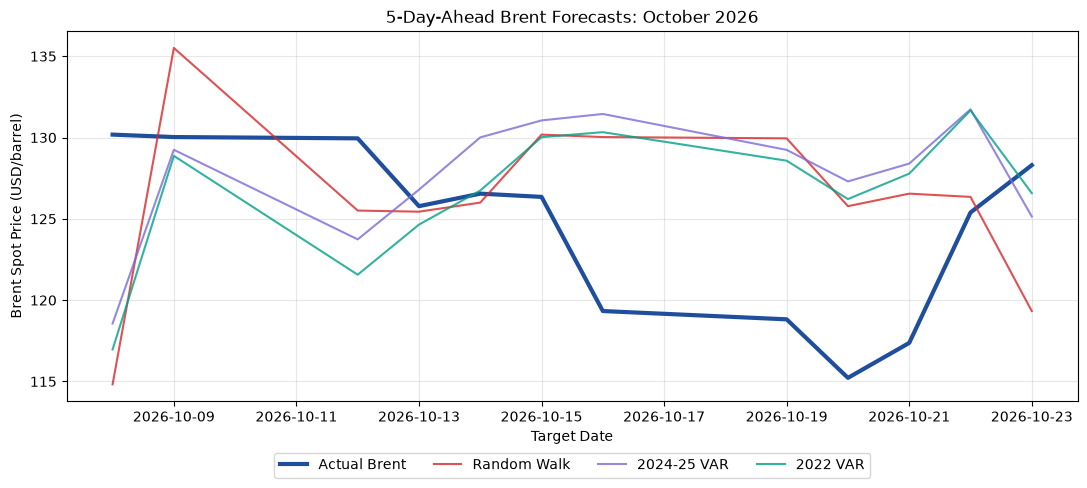

In [ ]:
VARS_2024_25 = ["log_return", "wti", "ovx", "usd", "vix", "invt_weekly_change"]   # picked on 2024-25 in forecast5.ipynb
LAG_2024_25 = 5
october_args = dict(horizon=H, **TESTS["October 2026"])

october = {
    "Random Walk": all_results["October 2026"]["Random Walk"],
    "2024-25 VAR": walk_forward(df_var, forecast_funct=var_forecast, cols=VARS_2024_25, lags=LAG_2024_25, **october_args),
    "2022 VAR": all_results["October 2026"]["VAR"],
}

plot_forecasts(october, f"{H}-Day-Ahead Brent Forecasts: October 2026")

The VAR picked on 2022 had the smaller average error (MAPE 5.3032 vs 5.6583) and was closer on 8 of 12 days.